In [2519]:
import os
from os.path import join
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from matplotlib import pyplot as plt
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

kagglehub.login()

# Download latest version
path = kagglehub.competition_download('titanic')

print("Path to competition files:", path)

Path to competition files: /Users/vyankov/.cache/kagglehub/competitions/titanic


In [2520]:
print('The scikit-learn version is {}.'.format(sklearn.__version__))

The scikit-learn version is 1.9.1.


In [2521]:
random_state=42
max_depth=10 # default=None
threshold = 0.5
min_samples_split = 50 # default=2
min_samples_leaf = 10 # default=1

In [2522]:
os.listdir(path)

['test.csv', 'train.csv', 'gender_submission.csv']

In [2523]:
train = pd.read_csv(Path(join(path, 'train.csv')))
test = pd.read_csv(Path(join(path, 'test.csv')))

In [2524]:
print('Train shape:', train.shape)  # 891 rows, 12 columns
print('Test shape :', test.shape)   # 418 rows, 11 columns (no Survived column)
train.head()

Train shape: (891, 12)
Test shape : (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2525]:
train.info()

print()
print('Missing values in train:')
print(train.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing values in train:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked 

Overall survival rate: 38.4%
Survived
0    549
1    342
Name: count, dtype: int64


Text(0, 0.5, 'Passengers')

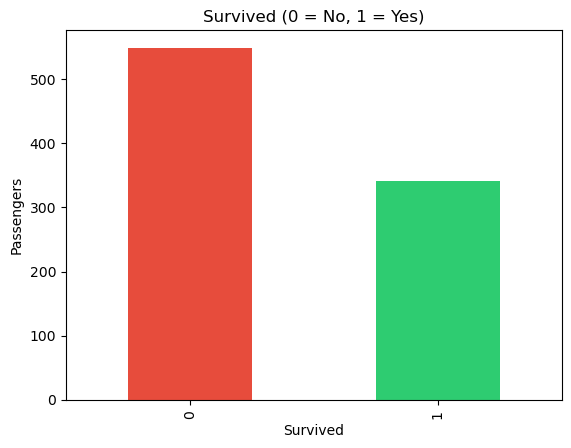

In [2526]:
survival_rate = train['Survived'].mean()
print(f'Overall survival rate: {survival_rate:.1%}')

counts = train['Survived'].value_counts().sort_index()
print(counts)
counts.plot(kind='bar', color=['#e74c3c', '#2ecc71'])
plt.title('Survived (0 = No, 1 = Yes)')
plt.xlabel('Survived')
plt.ylabel('Passengers')

Sex
female    74.2%
male      18.9%
Name: Survived, dtype: object

Survived     0     1
Sex                 
female    25.8  74.2
male      81.1  18.9


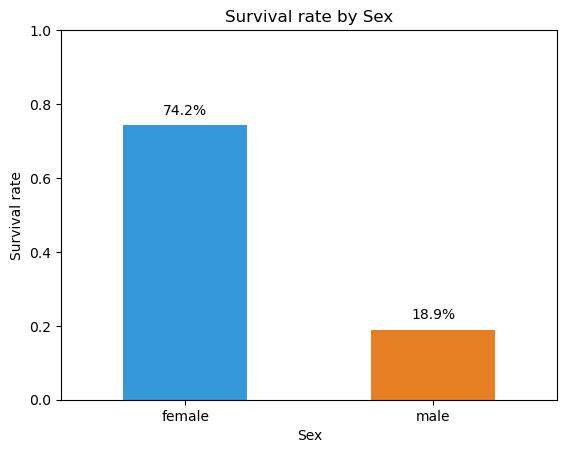

In [2527]:
sex_survival = train.groupby('Sex')['Survived'].mean()
print(sex_survival.apply(lambda x: f'{x:.1%}'))
print()
print(pd.crosstab(train['Sex'], train['Survived'], normalize='index').mul(100).round(1))

sex_survival.plot(kind='bar', color=['#3498db', '#e67e22'])
plt.title('Survival rate by Sex')
plt.ylabel('Survival rate')
plt.ylim(0, 1)
plt.xticks(rotation=0)
for i, v in enumerate(sex_survival):
    plt.text(i, v + 0.03, f'{v:.1%}', ha='center')
plt.show()

Pclass
1    63.0%
2    47.3%
3    24.2%
Name: Survived, dtype: object


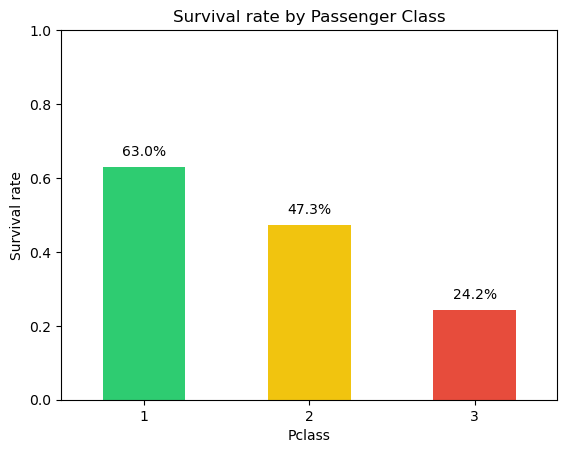

In [2528]:
pclass_survival = train.groupby('Pclass')['Survived'].mean()
print(pclass_survival.apply(lambda x: f'{x:.1%}'))

pclass_survival.plot(kind='bar', color=['#2ecc71', '#f1c40f', '#e74c3c'])
plt.title('Survival rate by Passenger Class')
plt.xlabel('Pclass')
plt.ylabel('Survival rate')
plt.ylim(0, 1)
plt.xticks(rotation=0)
for i, v in enumerate(pclass_survival):
    plt.text(i, v + 0.03, f'{v:.1%}', ha='center')
plt.show()

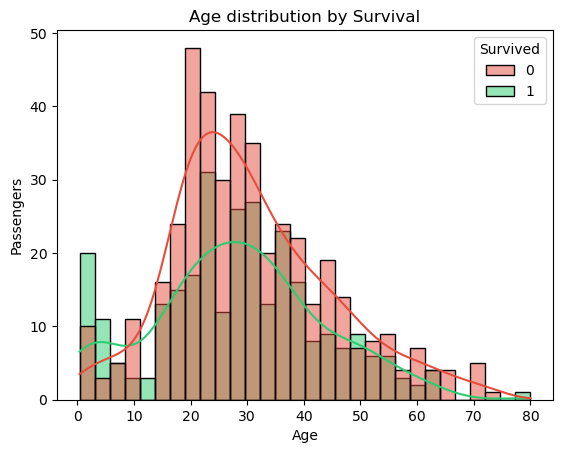

In [2529]:
sns.histplot(data=train, x='Age', hue='Survived', bins=30, kde=True,
             palette=['#e74c3c', '#2ecc71'])
plt.title('Age distribution by Survival')
plt.xlabel('Age')
plt.ylabel('Passengers')
plt.show()

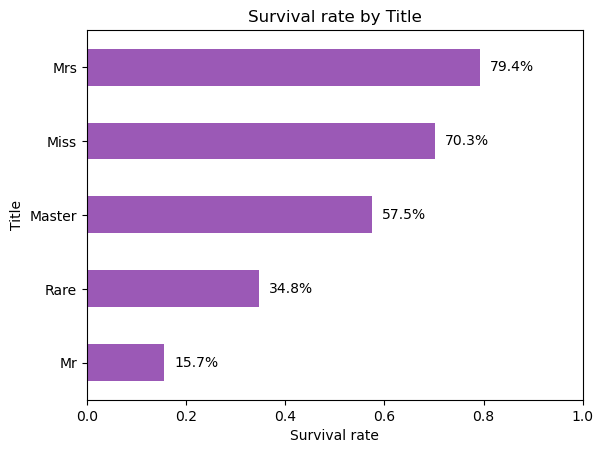

In [2530]:
titled = train.copy()
titled['Title'] = titled['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
titled['Title'] = titled['Title'].replace(
    ['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr',
     'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
titled['Title'] = titled['Title'].replace(['Mlle', 'Ms'], 'Miss')
titled['Title'] = titled['Title'].replace('Mme', 'Mrs')
title_survival = titled.groupby('Title')['Survived'].mean().sort_values()

title_survival.plot(kind='barh', color='#9b59b6')
plt.title('Survival rate by Title')
plt.xlabel('Survival rate')
plt.xlim(0, 1)
for i, v in enumerate(title_survival):
    plt.text(v + 0.02, i, f'{v:.1%}', va='center')
plt.show()

In [2531]:
train[train['Ticket'].str.contains('347082')]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
13,14,0,3,"Andersson, Mr. Anders Johan",male,39.0,1,5,347082,31.275,NaN,S
119,120,0,3,"Andersson, Miss. Ellis Anna Maria",female,2.0,4,2,347082,31.275,NaN,S
541,542,0,3,"Andersson, Miss. Ingeborg Constanzia",female,9.0,4,2,347082,31.275,NaN,S
542,543,0,3,"Andersson, Miss. Sigrid Elisabeth",female,11.0,4,2,347082,31.275,NaN,S
610,611,0,3,"Andersson, Mrs. Anders Johan (Alfrida Konstant...",female,39.0,1,5,347082,31.275,NaN,S
813,814,0,3,"Andersson, Miss. Ebba Iris Alfrida",female,6.0,4,2,347082,31.275,NaN,S
850,851,0,3,"Andersson, Master. Sigvard Harald Elias",male,4.0,4,2,347082,31.275,NaN,S


In [2532]:
# ticket = train.groupby('Ticket')

train[train['Name'].str.contains('Andersson')].iloc[0].str.extract(r'([A-Za-z]+)\,', expand=False)

PassengerId          NaN
Survived             NaN
Pclass               NaN
Name           Andersson
Sex                  NaN
Age                  NaN
SibSp                NaN
Parch                NaN
Ticket               NaN
Fare                 NaN
Cabin                NaN
Embarked             NaN
Name: 13, dtype: object

In [2533]:
def add_basic_features(df):
    df = df.copy()
    t = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
    t = t.replace(['Mlle', 'Ms'], 'Miss').replace('Mme', 'Mrs')
    df['Title'] = t.where(t.isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Rare')
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    df['Sex'] = (df['Sex'] == 'female').astype(int)
    return df

class GroupSurvival(BaseEstimator, TransformerMixin):
    """Частка тих, хто вижив, серед інших людей з тим самим квитком (тільки з train)."""

    def fit(self, X, y):
        df = X[['Ticket']].assign(y=np.asarray(y))
        g = df.groupby('Ticket')['y']
        self.sum_ = g.sum()
        self.cnt_ = g.count()
        return self

    def fit_transform(self, X, y):
        # для train: leave-one-out, без самого пасажира
        self.fit(X, y)
        s = X['Ticket'].map(self.sum_) - np.asarray(y)
        c = X['Ticket'].map(self.cnt_) - 1
        return self._out(X, s, c)

    def transform(self, X):
        # для валідації та test: уся група з train
        s = X['Ticket'].map(self.sum_)
        c = X['Ticket'].map(self.cnt_)
        return self._out(X, s, c)

    def _out(self, X, s, c):
        X = X.copy()
        X['GroupSurvival'] = (s / c).where(c > 0, 0.5).fillna(0.5)
        X['HasGroupInfo'] = (c > 0).fillna(False).astype(int)
        return X

class AgeByTitleImputer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.medians_ = X.groupby('Title')['Age'].median()
        self.global_ = X['Age'].median()
        return self

    def transform(self, X):
        X = X.copy()
        fill = X['Title'].map(self.medians_).fillna(self.global_)
        X['Age'] = X['Age'].fillna(fill)
        return X

def make_preprocess():
    preprocess = ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), ['Age', 'Fare', 'FamilySize', 'Pclass', 'Sex']),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['Title', 'Embarked']),
    ])
    return preprocess

def build_pipeline(model):
    pipeline = Pipeline([
        ('group', GroupSurvival()),
        ('age', AgeByTitleImputer()),
        ('prep', make_preprocess()),
        ('model', model),
    ])
    return pipeline


In [2534]:
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=max_depth,
    random_state=random_state,
    min_samples_split=min_samples_split,
    min_samples_leaf=min_samples_leaf
)
dt_model_pipe = build_pipeline(dt_model)

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=random_state,
    criterion="gini",
    max_depth=max_depth,
    min_samples_split=min_samples_split,
    min_samples_leaf=min_samples_leaf
)
rf_model_pipe = build_pipeline(rf_model)

xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=random_state,
    max_depth=max_depth,
    learning_rate=0.04,
)
xgb_model_pipe = build_pipeline(xgb_model)

lr_model = Pipeline([('scaler', StandardScaler()),
                   ('lr', LogisticRegression(max_iter=1000, C=0.5, random_state=42))])
lr_model_pipe = build_pipeline(lr_model)

In [2535]:
X = add_basic_features(train)
X['Embarked'] = X['Embarked'].fillna('S')
y = train['Survived']

def run_RSKF(pipe):
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
    scores = cross_val_score(pipe, X, y, cv=cv)
    print(f'{scores.mean():.4f} ± {scores.std():.4f}')

run_RSKF(dt_model_pipe)
run_RSKF(rf_model_pipe)
run_RSKF(xgb_model_pipe)
run_RSKF(lr_model_pipe)

0.8093 ± 0.0238
0.8236 ± 0.0242
0.8273 ± 0.0206
0.8277 ± 0.0229


In [2536]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=random_state, stratify=y)

lr_model_pipe.fit(X_train, y_train)

val_accuracy = lr_model_pipe.score(X_val, y_val)
print(f'Validation accuracy: {val_accuracy:.4f}  ({val_accuracy:.1%})')

Validation accuracy: 0.8436  (84.4%)


In [2538]:
X_test = add_basic_features(test)
test_ids = test['PassengerId'].values
X_test.drop('PassengerId', axis=1, inplace=True)
X_test['Embarked'] = X_test['Embarked'].fillna('S')
lr_model_pipe.fit(X, y)
probabilities = lr_model_pipe.predict_proba(X_test)[:, 1]
preds_test = (probabilities >= threshold).astype(int)

output = pd.DataFrame({'PassengerId': test_ids,
                       'Survived': preds_test})
output.to_csv('submission.csv', index=False)